# 电商销售分析

**业务问题：** 销售额、客单价、月份、类别和地区的表现如何？

> 本项目使用仓库内的合成教学数据，不代表真实企业业绩。笔记本复用同目录分析模块，确保脚本、结果表与图表口径一致。请使用 Python 3.11 并从仓库内部启动 Jupyter。

## 1. 读取数据

根据当前目录向上定位仓库，不在 notebook 中依赖 `__file__`，也不硬编码电脑路径。

In [1]:
from pathlib import Path
import importlib.util
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
from io import BytesIO

# Works when Jupyter starts at the repo root, project directory or notebook directory.
start = Path.cwd().resolve()
root = next((p for p in (start, *start.parents)
             if (p / 'projects' / 'ecommerce-sales-analysis' / 'scripts' / 'analyze.py').is_file()), None)
if root is None:
    raise FileNotFoundError('请在本仓库内启动 Jupyter，或先切换到仓库根目录。')
project_dir = root / 'projects' / 'ecommerce-sales-analysis'
module_path = project_dir / 'scripts' / 'analyze.py'
spec = importlib.util.spec_from_file_location('ecommerce_sales_analysis', module_path)
analysis = importlib.util.module_from_spec(spec)
spec.loader.exec_module(analysis)
df = analysis.load_data()
assert not df.empty
print('Input rows:', len(df))
display(df.head())


Input rows: 50


,order_id,order_date,customer_id,product_category,product_name,quantity,unit_price,region,payment_method,revenue,month
0,10001,2024-01-05,C001,Electronics,Smartphone,1,2999.0,East,Credit Card,2999.0,2024-01
1,10002,2024-01-08,C002,Fashion,T-Shirt,2,129.0,West,Alipay,258.0,2024-01
2,10003,2024-01-12,C003,Home,Coffee Maker,1,499.0,North,Credit Card,499.0,2024-01
3,10004,2024-01-15,C004,Electronics,Laptop,1,5999.0,South,WeChat Pay,5999.0,2024-01
4,10005,2024-01-20,C005,Fashion,Jeans,1,399.0,East,Alipay,399.0,2024-01


## 2. 数据质量检查

报告缺失与整行重复。重复事件可能是真实行为，不应未经业务判断直接删除。分析模块进一步校验必要字段和数值范围。

In [2]:
display(df.isna().sum().to_frame('missing_count'))
print('Exact duplicate rows:', int(df.duplicated().sum()))

,missing_count
order_id,0
order_date,0
customer_id,0
product_category,0
product_name,0
quantity,0
unit_price,0
region,0
payment_method,0
revenue,0


Exact duplicate rows: 0


## 3. 指标定义与独立复算

订单销售额 = quantity × unit_price；总销售额按订单金额求和；客单价 = 总销售额 / 去重订单数。这里只描述样本，不把一年数据中的波动当作已经证实的季节性。

In [3]:
orders = df.assign(revenue=df['quantity'] * df['unit_price'])
summary = pd.DataFrame([{
    'orders': orders['order_id'].nunique(),
    'revenue': orders['revenue'].sum(),
    'average_order_value': orders['revenue'].sum() / orders['order_id'].nunique(),
}])
display(summary.round(2))
category_check = orders.groupby('product_category')['revenue'].sum().sort_values(ascending=False)
display(category_check.to_frame())

,orders,revenue,average_order_value
0,50,80860.0,1617.2


,revenue
product_category,
Electronics,54778.0
Home,17313.0
Fashion,8769.0


## 4. 完整分析结果

下面调用可复用的 `analyze(df)`，展示结果表；业务口径详见相邻项目说明和脚本。

In [4]:
results = analysis.analyze(df)
assert isinstance(results, dict) and results
for name, table in results.items():
    print(f'--- {name} ---')
    with pd.option_context('display.max_rows', 50, 'display.max_columns', 20):
        display(table)

--- overview ---


,order_count,customer_count,units,revenue,average_order_value,first_order_date,last_order_date,q4_revenue,q4_revenue_share_pct
0,50,50,60,80860.0,1617.2,2024-01-05,2024-12-30,36525.0,45.170665


--- monthly_sales ---


,month,orders,units,revenue,revenue_share_pct,average_order_value
0,2024-01,6,7,10413.0,12.877814,1735.500000
1,2024-02,4,4,4096.0,5.065545,1024.000000
2,2024-03,4,4,5596.0,6.920604,1399.000000
3,2024-04,4,4,11396.0,14.093495,2849.000000
4,2024-05,4,4,3796.0,4.694534,949.000000
5,2024-06,3,3,5047.0,6.241652,1682.333333
6,2024-07,3,3,687.0,0.849617,229.000000
7,2024-08,3,3,707.0,0.874351,235.666667
8,2024-09,3,3,2597.0,3.211724,865.666667
9,2024-10,3,5,1585.0,1.960178,528.333333


--- category_sales ---


...

,region,orders,units,revenue,revenue_share_pct
0,West,13,16,22824.0,28.226564
1,South,12,15,20215.0,25.000000
2,North,12,13,19047.0,23.555528
3,East,13,16,18774.0,23.217907


--- top_products ---


,product_name,orders,units,revenue,revenue_share_pct
0,Laptop,3,4,23996.0,29.675983
1,Smartphone,2,3,8997.0,11.126639
2,Camera,1,1,4599.0,5.687608
3,Gaming Console,1,1,3999.0,4.945585
4,Headphones,2,4,3596.0,4.447193


--- payment_methods ---


,payment_method,orders,order_share_pct
0,Credit Card,18,36.0
1,Alipay,16,32.0
2,WeChat Pay,16,32.0


## 5. 可视化

图表与脚本使用同一结果字典，不另写一套计算逻辑。

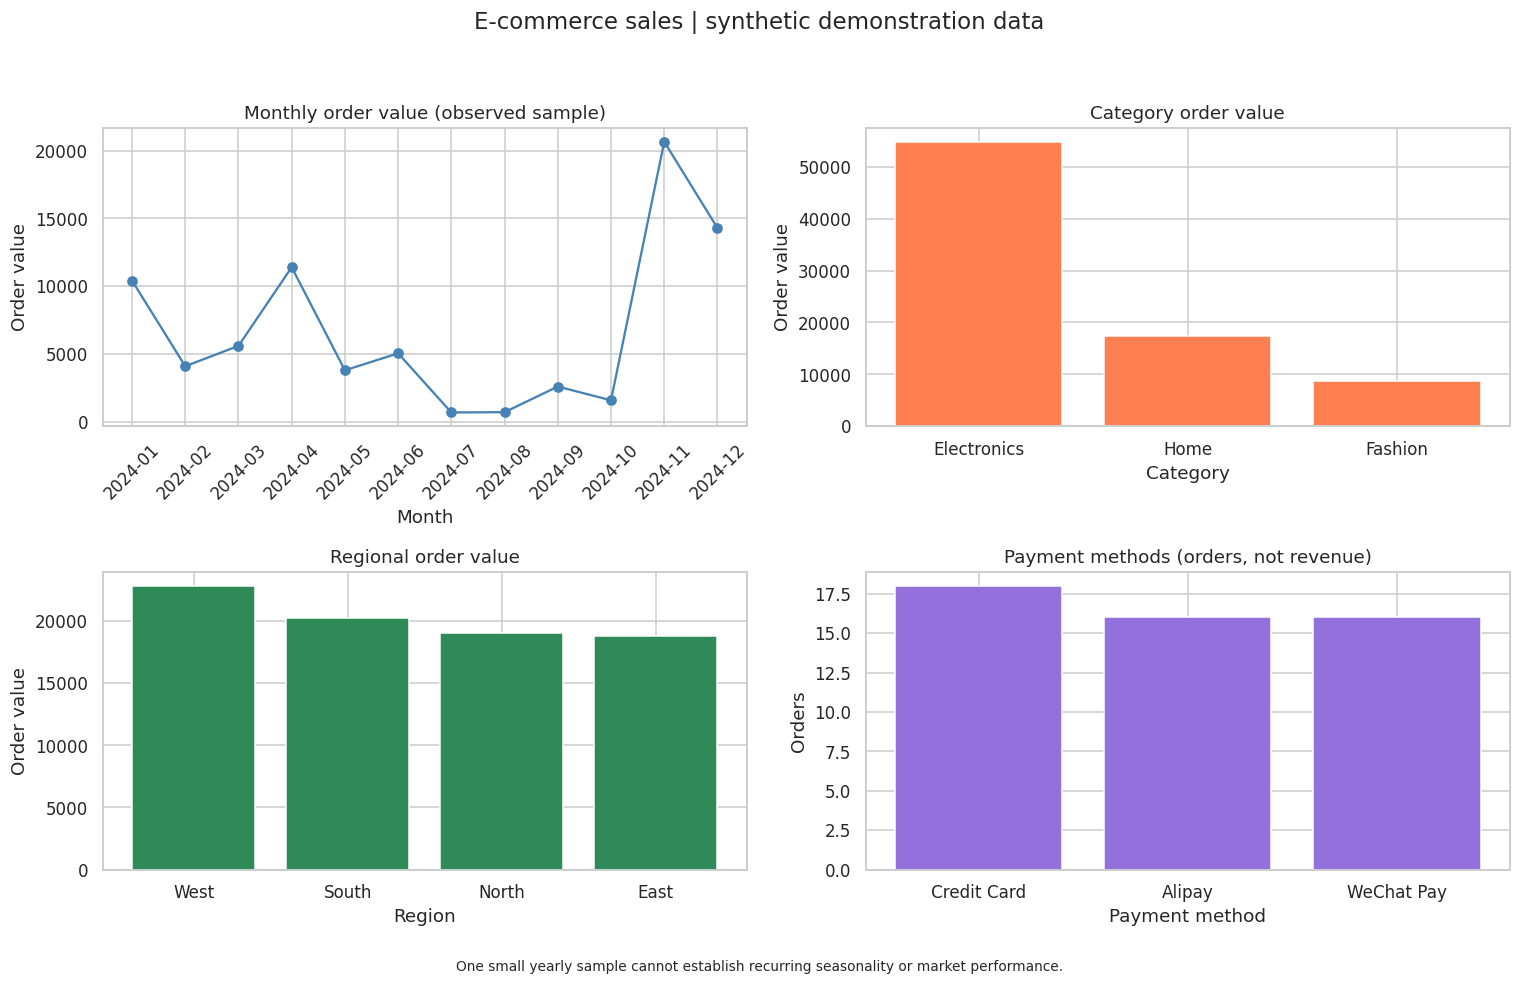

In [5]:
fig = analysis.plot_dashboard(results)
# Explicit PNG display also works with the headless Agg backend.
image = BytesIO()
fig.savefig(image, format='png', dpi=110, bbox_inches='tight')
display(Image(data=image.getvalue()))
plt.close(fig)

## 6. 结论、建议与边界

当前合成样本共 50 单，总销售额 80,860 元；Electronics 高于 Home，Fashion 排第三。11 月销售额较高只是样本描述。没有成本、退货和流量数据，不能由销售额直接推断利润、营销效果或因果关系。下一步应接入更大规模真实数据、补齐退货/成本口径，并在建议落地后衡量结果。

**复现检查：** 从首个代码单元开始运行全部单元；仓库统一验证命令为 `python scripts/validate_portfolio.py`。生成笔记本和实际执行笔记本是两个不同步骤，执行结果以验证报告为准。